# Chemia ligandów a podobieństwo profili mutacyjnych

Czy podobieństwo chemiczne ligandów MOR wiąże się z podobieństwem ich profili wrażliwości na mutacje, niezależnie od skuteczności agonistycznej?

## 1. Dane i konfiguracja

Wczytujemy struktury ligandów z `raw_smiles.tsv` i przygotowujemy katalog wyników. Do porównania z profilami mutacyjnymi potrzebny jest plik `results/01_reproduce_ligand_profiles/ligand_profile_pairs.csv`, generowany w notatniku 01.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import (
    Crippen,
    Descriptors,
    Lipinski,
    rdFingerprintGenerator,
    rdMolDescriptors,
)
from rdkit.Chem.MolStandardize import rdMolStandardize
from scipy import stats

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents)
                     if (p / "pyproject.toml").is_file()
                     and (p / "data/raw").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate project root.")
RAW_DATA_DIR = PROJECT_ROOT / "data/raw"
OUTPUT_DIR = PROJECT_ROOT / "results/02_ligand_chemistry"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ligand_df = pd.read_table(RAW_DATA_DIR / "raw_smiles.tsv")

## 2. Deskryptory fizykochemiczne

Kanoniczne zapisy SMILES służą do obliczenia deskryptorów RDKit i fingerprintów Morgana (promień 2, 2048 bitów, bez uwzględniania chiralności); nie usuwamy soli ani nie neutralizujemy ładunków. Kolory mapy przedstawiają deskryptory standaryzowane w obrębie każdej kolumny, a liczby w komórkach pokazują wartości oryginalne.

In [2]:
DESCRIPTOR_COLS = [
    "MolWt", "LogP", "TPSA", "HBD", "HBA",
    "RotBonds", "RingCount", "FractionCSP3", "Ro5_violations"
]

def sanitize_smiles(smiles, desalt=False, uncharge=False):
    if not isinstance(smiles, str):
        return None

    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    try:
        if desalt:
            fragment_chooser = rdMolStandardize.LargestFragmentChooser()
            mol = fragment_chooser.choose(mol)

        if uncharge:
            uncharger = rdMolStandardize.Uncharger()
            mol = uncharger.uncharge(mol)

        Chem.SanitizeMol(mol)
        return Chem.MolToSmiles(mol, isomericSmiles=True, canonical=True)

    except Exception:
        return None

def generate_mol(smiles):
    if not isinstance(smiles, str):
        return None

    try:
        return Chem.MolFromSmiles(smiles)
    except Exception:
        return None

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048,
    includeChirality=False,
)

def generate_fp(mol):
    if mol is None:
        raise ValueError("Cannot generate a fingerprint for an invalid molecule.")

    return morgan_generator.GetFingerprintAsNumPy(mol)

def calculate_rdkit_descriptors(mol):
    if mol is None:
        return {col: np.nan for col in DESCRIPTOR_COLS}

    mw = Descriptors.MolWt(mol)
    logp = Crippen.MolLogP(mol)
    tpsa = rdMolDescriptors.CalcTPSA(mol)
    hbd = Lipinski.NumHDonors(mol)
    hba = Lipinski.NumHAcceptors(mol)

    return {
        "MolWt": mw,
        "LogP": logp,
        "TPSA": tpsa,
        "HBD": hbd,
        "HBA": hba,
        "RotBonds": Lipinski.NumRotatableBonds(mol),
        "RingCount": Lipinski.RingCount(mol),
        "FractionCSP3": Lipinski.FractionCSP3(mol),
        "Ro5_violations": sum([
            mw > 500,
            logp > 5,
            hbd > 5,
            hba > 10,
        ]),
    }

ligand_df["sanitized_smiles"] = ligand_df["smiles"].apply(sanitize_smiles)
ligand_df["mol"] = ligand_df["sanitized_smiles"].apply(generate_mol)
ligand_df["fingerprint"] = ligand_df["mol"].apply(generate_fp)

ligand_features_df = ligand_df.copy()

descriptor_df = pd.DataFrame(
    [
        calculate_rdkit_descriptors(mol)
        for mol in ligand_features_df["mol"]
    ],
    index=ligand_features_df.index,
).reindex(columns=DESCRIPTOR_COLS)

ligand_features_df[DESCRIPTOR_COLS] = descriptor_df

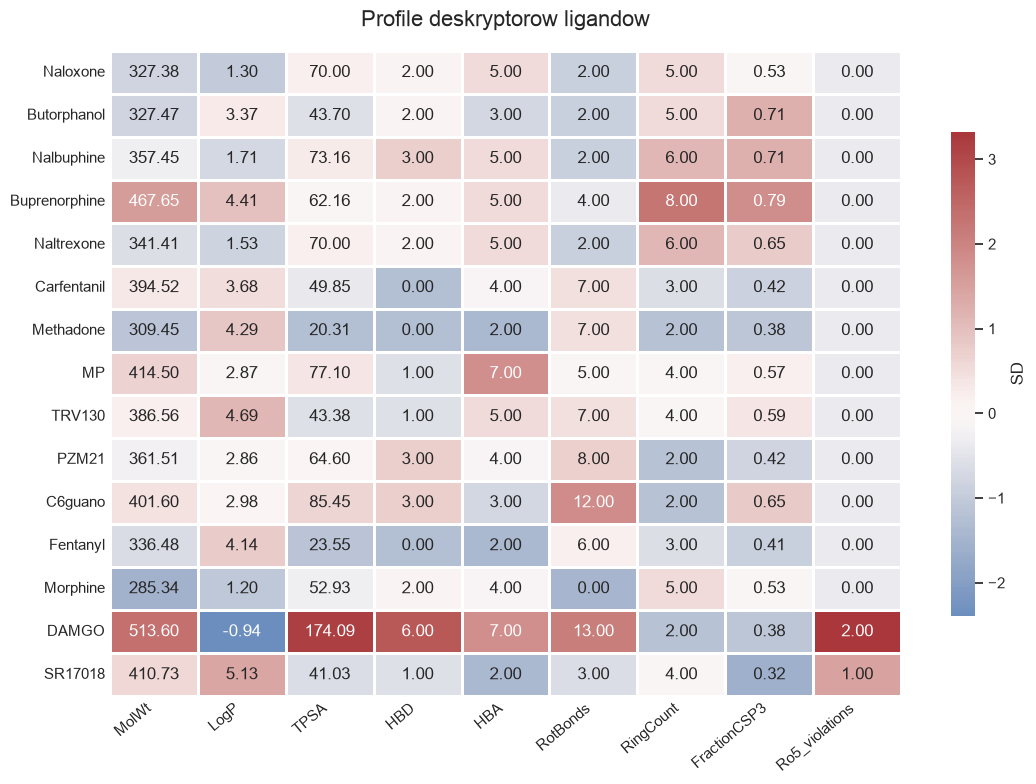

In [3]:
features = (
    ligand_features_df[DESCRIPTOR_COLS]
    .astype(float)
    .replace([np.inf, -np.inf], np.nan)
)

std = features.std(ddof=0).replace(0, 1)
scaled = (features - features.mean()) / std

labels = ligand_df["ligand"]

sns.set_theme(style="white", context="notebook")

fig, ax = plt.subplots(
    figsize=(max(8, len(DESCRIPTOR_COLS) * 1.25), 8)
)

sns.heatmap(
    scaled,
    cmap="vlag",
    center=0,
    annot=features,      # liczby w komorkach: oryginalne wartosci
    fmt=".2f",
    linewidths=0.8,
    linecolor="white",
    yticklabels=labels,
    cbar_kws={"label": "SD", "shrink": 0.75},
    ax=ax,
)

ax.set_title("Profile deskryptorow ligandow", fontsize=16, pad=18)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="both", length=0)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)

fig.tight_layout()
plt.show()

## 3. Podobieństwo strukturalne ligandów

Współczynnik Tanimoto porównuje pary fingerprintów Morgana: większa wartość oznacza większe podobieństwo zakodowanych cech strukturalnych. Macierz podobieństwa zapisujemy do `ligand_tanimoto_similarity.csv`.

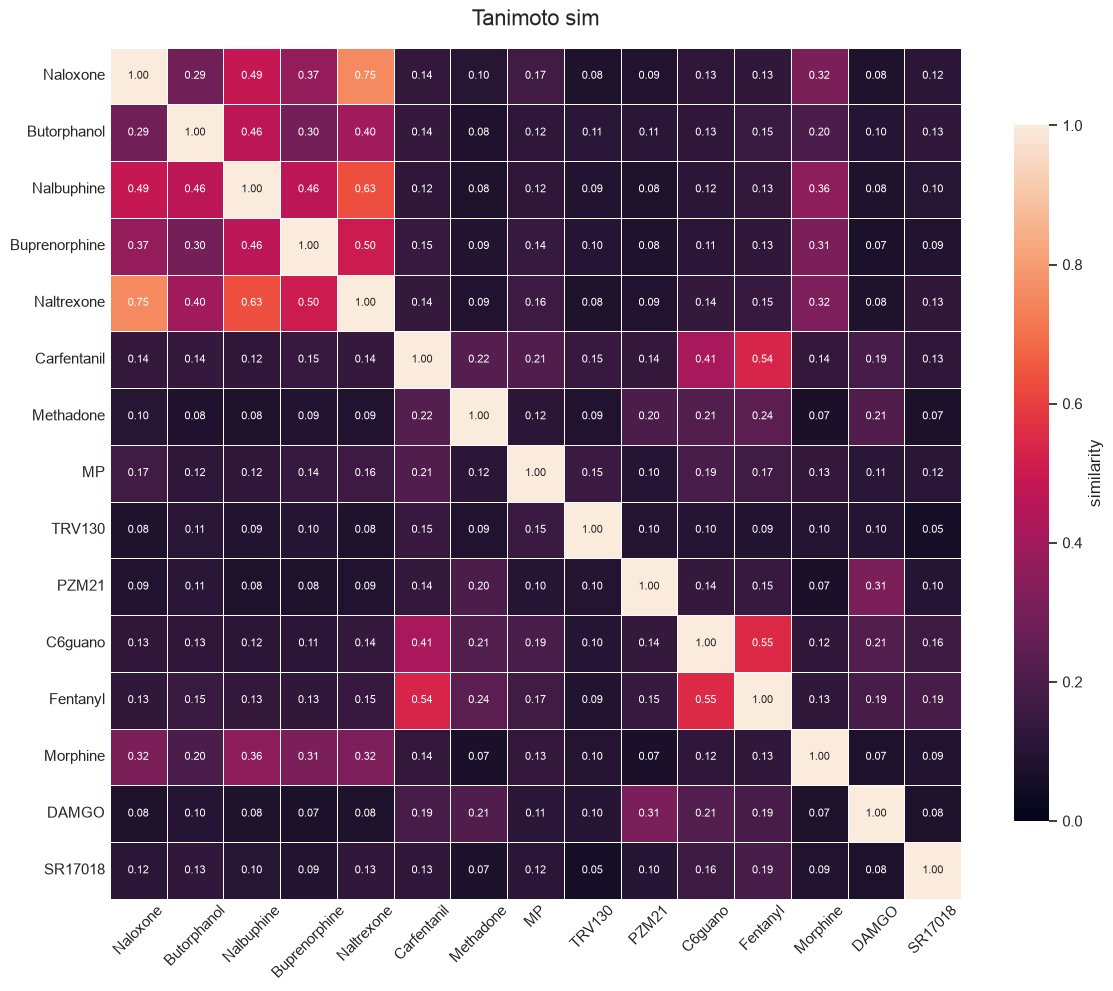

In [ ]:
def tanimoto_matrix(ligand_df):
    labels = ligand_df["ligand"]
    # jeden binarny fingerprint na wiersz
    fps = np.stack(ligand_df["fingerprint"].to_numpy()).astype(np.int64)

    intersections = fps @ fps.T
    bit_counts = fps.sum(axis=1)
    unions = bit_counts[:, None] + bit_counts[None, :] - intersections

    similarities = np.divide(
        intersections,
        unions,
        out=np.ones_like(intersections, dtype=float),
        where=unions != 0,
    )

    return pd.DataFrame(
        similarities,
        index=labels,
        columns=labels,
    )

tanimoto_df = tanimoto_matrix(ligand_df)

labels = ligand_df["ligand"]

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    tanimoto_df,
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    linecolor="white",
    xticklabels=labels,
    yticklabels=labels,
    annot_kws={"fontsize": 8},
    cbar_kws={"label": "similarity", "shrink": 0.8},
    ax=ax,
)

ax.set_title("Tanimoto sim", fontsize=16, pad=16)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="both", length=0)
plt.setp(ax.get_xticklabels(), rotation=45)
plt.setp(ax.get_yticklabels(), rotation=0)

fig.tight_layout()
plt.show()

tanimoto_df.to_csv(
    OUTPUT_DIR / "ligand_tanimoto_similarity.csv",
    index_label="ligand",
)

## 4. Chemia a profile mutacyjne

Dla każdej pary ligandów zestawiamy podobieństwo Tanimoto z korelacją Pearsona ich profili mutacyjnych i zapisujemy dane do `ligand_pairs_combined.csv`. Wykres oraz korelacja rang Spearmana opisują surową zależność między tymi miarami, przed kontrolą Emax.

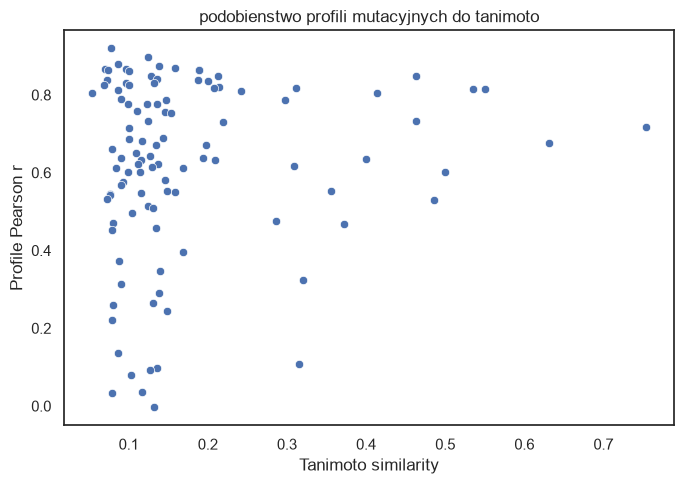

Korelacja Spearmana: 0.066


In [5]:
dms_pairs = pd.read_csv(PROJECT_ROOT/ "results/01_reproduce_ligand_profiles/ligand_profile_pairs.csv")

combined = dms_pairs[["ligand_a", "ligand_b", "pearson_r"]].copy()
combined["tanimoto_similarity"] = [
    tanimoto_df.loc[a, b]
    for a, b in zip(combined["ligand_a"], combined["ligand_b"], strict=False)
]

combined.to_csv(OUTPUT_DIR / "ligand_pairs_combined.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(
    data=combined, x="tanimoto_similarity", y="pearson_r", ax=ax,
)
ax.set(
    xlabel="Tanimoto similarity",
    ylabel="Profile Pearson r",
    title="podobienstwo profili mutacyjnych do tanimoto",
)
fig.tight_layout()
plt.show()

spearman = stats.spearmanr(combined["pearson_r"], combined["tanimoto_similarity"])
print(f"Korelacja Spearmana: {spearman.statistic:.3f}")

## 5. Kontrola skuteczności ligandów (Emax)

Dla par z dostępnym `tp_emax` wyznaczamy średnią skuteczność i bezwzględną różnicę Emax. Model liniowy opisuje korelację profili za pomocą tych dwóch cech oraz podobieństwa Tanimoto, pozwalając ocenić wkład chemii przy stałych wartościach cech Emax.

In [ ]:
ligand_summary = pd.read_csv(
    RAW_DATA_DIR / "05_ligand_summary.csv"
)

emax = ligand_summary.set_index("ligand")["tp_emax"]

combined["emax_a"] = combined["ligand_a"].map(emax)
combined["emax_b"] = combined["ligand_b"].map(emax)

analysis_pairs = combined.dropna(
    subset=["emax_a", "emax_b"]
).copy()

analysis_pairs["emax_mean"] = (
    analysis_pairs["emax_a"] + analysis_pairs["emax_b"]
) / 2

analysis_pairs["emax_gap"] = (
    analysis_pairs["emax_a"] - analysis_pairs["emax_b"]
).abs()

predictors = ["tanimoto_similarity", "emax_mean", "emax_gap"]

# kolumna jedynek odpowiada wyrazowi wolnemu
X = np.column_stack([
    np.ones(len(analysis_pairs)),
    analysis_pairs[predictors].to_numpy(),
])

y = analysis_pairs["pearson_r"].to_numpy()

coefficients, _, _, _ = np.linalg.lstsq(X, y, rcond=None)

coefficients = pd.Series(
    coefficients,
    index=["intercept", *predictors],
    name="coefficient",
)

display(coefficients)

delta_r = coefficients["tanimoto_similarity"] * 0.1

print(
    f"Wzrost Tanimoto o 0.1 odpowiada zmianie "
    f"przewidywanego pearson_r o {delta_r:+.4f}."
)

intercept              0.662493
tanimoto_similarity    0.167771
emax_mean              0.002160
emax_gap              -0.007412
Name: coefficient, dtype: float64

Wzrost Tanimoto o 0.1 odpowiada zmianie przewidywanego pearson_r o +0.0168.


## 6. Korelacja częściowa i test permutacyjny

Korelację częściową Pearsona obliczamy między resztami obu miar po usunięciu liniowego wpływu średniej i różnicy Emax. Test z 9999 wspólnymi permutacjami wierszy i kolumn macierzy reszt profili uwzględnia współdzielenie ligandów przez pary; dwustronne p porównuje bezwzględne wartości korelacji.

In [7]:
# Wyraz wolny oraz obie cechy efficacy, bez Tanimoto.
Z = X[:, [0, 2, 3]]

tanimoto = analysis_pairs["tanimoto_similarity"].to_numpy()

# Czesc profilu mutacyjnego niewyjasniona przez model efficacy.
beta_y = np.linalg.lstsq(Z, y, rcond=None)[0]
profile_residuals = y - Z @ beta_y

# Czesc podobienstwa chemicznego niewyjasniona przez ten sam model.
beta_t = np.linalg.lstsq(Z, tanimoto, rcond=None)[0]
tanimoto_residuals = tanimoto - Z @ beta_t

partial_r = np.corrcoef(
    tanimoto_residuals,
    profile_residuals,
)[0, 1]

ligand_order = pd.Index(sorted(
    set(analysis_pairs["ligand_a"])
    | set(analysis_pairs["ligand_b"])
))

# Polozenie obu ligandow kazdej pary w macierzy.
row_idx = ligand_order.get_indexer(analysis_pairs["ligand_a"])
col_idx = ligand_order.get_indexer(analysis_pairs["ligand_b"])

residual_matrix = np.zeros(
    (len(ligand_order), len(ligand_order))
)

# Wpisujemy reszty symetrycznie: A–B oraz B–A.
residual_matrix[row_idx, col_idx] = profile_residuals
residual_matrix[col_idx, row_idx] = profile_residuals

Czesciowa korelacja Pearsona: 0.252
Permutacyjne p: 0.0795


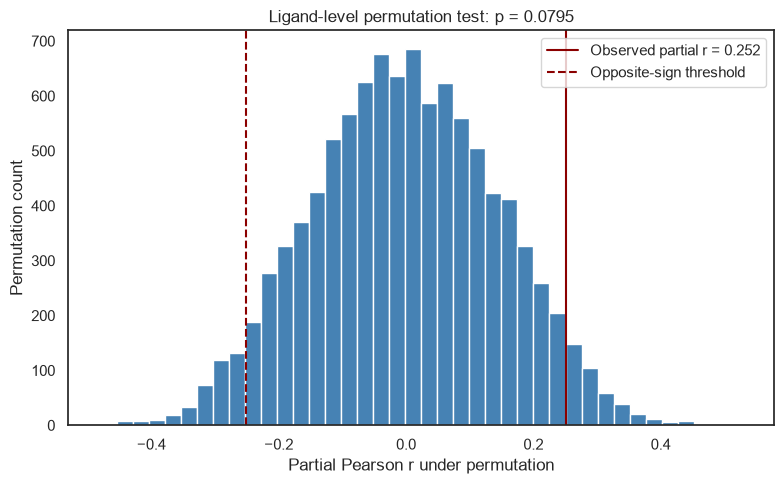

In [8]:
n_permutations = 9999
rng = np.random.default_rng(8)

permuted_correlations = np.empty(n_permutations)

# Ta czesc pozostaje stala we wszystkich permutacjach.
efficacy_prediction = Z @ beta_y

for i in range(n_permutations):
    permutation = rng.permutation(len(ligand_order))

    permuted_matrix = residual_matrix[
        np.ix_(permutation, permutation)
    ]
    permuted_residuals = permuted_matrix[row_idx, col_idx]

    y_permuted = efficacy_prediction + permuted_residuals

    beta_permuted = np.linalg.lstsq(
        Z, y_permuted, rcond=None
    )[0]
    new_residuals = y_permuted - Z @ beta_permuted

    permuted_correlations[i] = np.corrcoef(
        tanimoto_residuals,
        new_residuals,
    )[0, 1]

n_extreme = np.count_nonzero(
    np.abs(permuted_correlations) >= abs(partial_r) - 1e-12
)

p_permutation = (n_extreme + 1) / (n_permutations + 1)

print(f"Czesciowa korelacja Pearsona: {partial_r:.3f}")
print(f"Permutacyjne p: {p_permutation:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    permuted_correlations,
    bins=40,
    color="steelblue",
    edgecolor="white",
)

ax.axvline(
    partial_r,
    color="darkred",
    label=f"Observed partial r = {partial_r:.3f}",
)
ax.axvline(
    -partial_r,
    color="darkred",
    linestyle="--",
    label="Opposite-sign threshold",
)

ax.set(
    xlabel="Partial Pearson r under permutation",
    ylabel="Permutation count",
    title=f"Ligand-level permutation test: p = {p_permutation:.4f}",
)
ax.legend()

fig.tight_layout()
plt.show()

## 7. Porównanie modeli i diagnostyka

Sprawdzamy wrażliwość korelacji częściowej na kontrolę samej różnicy Emax oraz porównujemy R² i RMSE modeli opartych na chemii, Emax i obu źródłach informacji. Miary dotyczą dopasowania do tych samych danych, a wykresy reszt pomagają ocenić wzorce niewyjaśnione przez pełny model.

In [ ]:
# model kontrolny: wyraz wolny + roznica Emax
Z_gap = np.column_stack([
    np.ones(len(analysis_pairs)),
    analysis_pairs["emax_gap"].to_numpy(),
])

# reszty podobienstwa profili
beta_y_gap = np.linalg.lstsq(Z_gap, y, rcond=None)[0]
profile_residuals_gap = y - Z_gap @ beta_y_gap

# reszty podobienstwa chemicznego
beta_t_gap = np.linalg.lstsq(Z_gap, tanimoto, rcond=None)[0]
tanimoto_residuals_gap = tanimoto - Z_gap @ beta_t_gap

partial_r_gap = np.corrcoef(
    tanimoto_residuals_gap,
    profile_residuals_gap,
)[0, 1]

print(f"Srednia i roznica Emax: r = {partial_r:.3f}")
print(f"Tylko roznica Emax:    r = {partial_r_gap:.3f}")

models = {
    "Chemistry only": X[:, [0, 1]],
    "Efficacy only": Z,
    "Efficacy + chemistry": X,
}

total_variation = np.sum((y - y.mean()) ** 2)
results = []

for name, design in models.items():
    beta = np.linalg.lstsq(design, y, rcond=None)[0]
    residuals = y - design @ beta

    results.append({
        "model": name,
        "R2": 1 - np.sum(residuals ** 2) / total_variation,
        "RMSE": np.sqrt(np.mean(residuals ** 2)),
    })

model_comparison = pd.DataFrame(results).set_index("model")
display(model_comparison.round(4))

delta_r2 = (
    model_comparison.loc["Efficacy + chemistry", "R2"]
    - model_comparison.loc["Efficacy only", "R2"]
)
print(f"Przyrost R² po dodaniu chemii do Emax: {delta_r2:.4f}")

Srednia i roznica Emax: r = 0.252
Tylko roznica Emax:    r = 0.087


,R2,RMSE
model,,
Chemistry only,0.0255,0.2210
Efficacy only,0.8706,0.0805
Efficacy + chemistry,0.8788,0.0779


Przyrost R² po dodaniu chemii do Emax: 0.0082


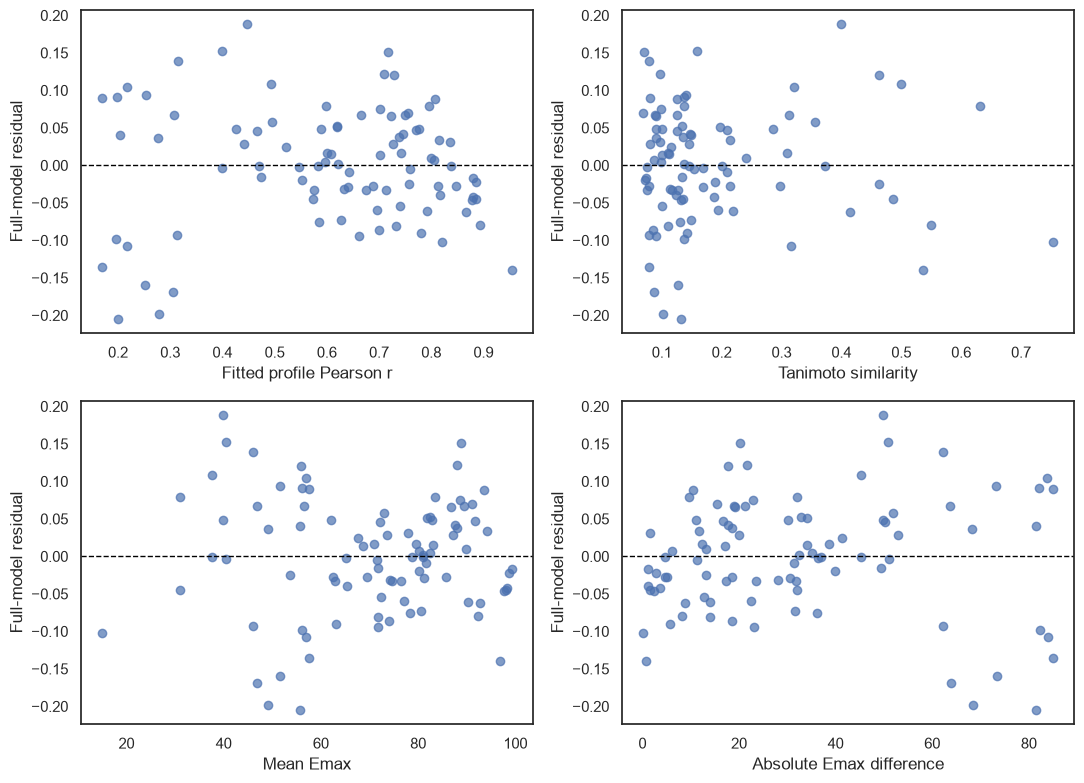

In [10]:
fitted = X @ coefficients.to_numpy()
full_residuals = y - fitted

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

diagnostic_variables = [
    (fitted, "Fitted profile Pearson r"),
    (analysis_pairs["tanimoto_similarity"], "Tanimoto similarity"),
    (analysis_pairs["emax_mean"], "Mean Emax"),
    (analysis_pairs["emax_gap"], "Absolute Emax difference"),
]

for ax, (values, label) in zip(axes.flat, diagnostic_variables):
    ax.scatter(values, full_residuals, alpha=0.7)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel(label)
    ax.set_ylabel("Full-model residual")

fig.tight_layout()
plt.show()

1. Reszty względem przewidywanego pearson_r — lewy górny

Przy niskich przewidywaniach, około 0,2–0,3, rozrzut reszt jest większy niż w większości obszaru wysokich przewidywań. Model ma więc mniej równomierną dokładność w różnych częściach zakresu.

Nie widać jednoznacznego, gładkiego łuku. Jest natomiast sygnał niejednakowej zmienności reszt, który warto traktować jako obserwację diagnostyczną, a nie formalnie potwierdzoną heteroskedastyczność.

2. Reszty względem Tanimoto — prawy górny

Nie widać wyraźnej krzywizny, która sugerowałaby konkretną nieliniową zależność od Tanimoto.

Większość punktów skupia się przy niskim podobieństwie chemicznym. Dla wysokiego Tanimoto mamy mało par, więc kształt zależności w tym obszarze jest słabo określony. Sam ten wykres nie uzasadnia dodawania np. kwadratu Tanimoto.

3. Reszty względem średniego Emax — lewy dolny

Punkty tworzą lokalne skupienia: przy średnim Emax około 40 przeważają dodatnie reszty, a około 50–60 występują duże odchylenia ujemne.

To sugeruje, że pojedynczy liniowy współczynnik średniego Emax nie opisuje całej struktury danych. Część skupień może jednak wynikać ze współdzielenia tych samych ligandów przez wiele par.

4. Reszty względem różnicy Emax — prawy dolny

Przy dużych różnicach Emax widać dwie grupy: dodatnie i silnie ujemne reszty. Sprawdziłem pary odpowiadające tym punktom: rozdzielenie wiąże się z naloksonem i naltreksonem.

Dla różnic Emax powyżej 65:
- pary z naloksonem mają ujemne reszty;
- pary z naltreksonem mają dodatnie reszty.
Przykładowo:
Para	Reszta pełnego modelu
Fentanyl–nalokson	−0,204
Fentanyl–naltrekson	+0,041
Morfina–nalokson	−0,107
Morfina–naltrekson	+0,105


Nalokson i naltrekson mają niemal identyczne tp_emax: 14,9 i 15,0. Mimo tego ich pary z silnymi agonistami odbiegają od przewidywań w przeciwnych kierunkach. Różnica pozostaje również po uwzględnieniu Tanimoto, ponieważ oglądamy reszty pełnego modelu.

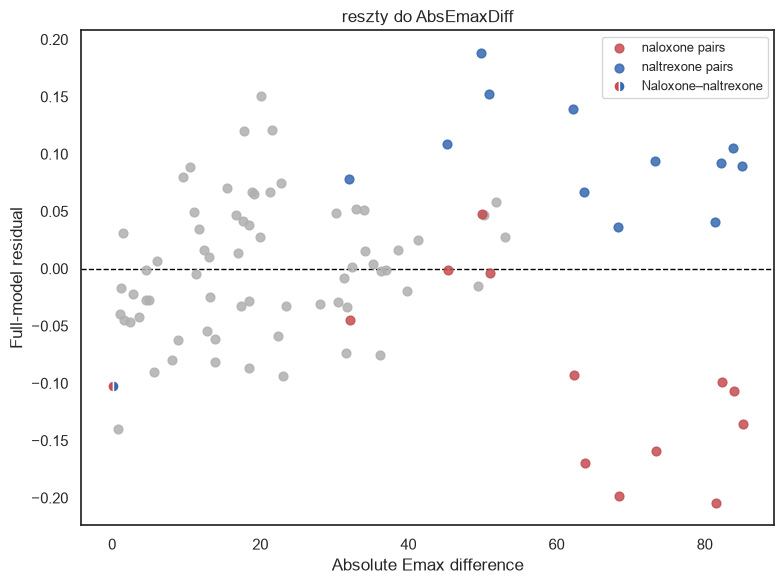

In [11]:
fitted = X @ coefficients.to_numpy()
full_residuals = y - fitted
pair_plot = analysis_pairs[["ligand_a", "ligand_b", "emax_gap"]].copy()
pair_plot["residual"] = full_residuals

has_naloxone = pair_plot[["ligand_a", "ligand_b"]].eq("Naloxone").any(axis=1)
has_naltrexone = pair_plot[["ligand_a", "ligand_b"]].eq("Naltrexone").any(axis=1)

fig, ax = plt.subplots(figsize=(8, 6))
for mask, color, label in [
    (~has_naloxone & ~has_naltrexone, "#b0b0b0", ""),
    (has_naloxone & ~has_naltrexone, "#c44e52", "naloxone pairs"),
    (has_naltrexone & ~has_naloxone, "#3569b0", "naltrexone pairs"),
]:
    subset = pair_plot.loc[mask]
    ax.scatter(subset["emax_gap"], subset["residual"],
               color=color, s=40, alpha=0.85, label=label, zorder=3)

shared = pair_plot.loc[has_naloxone & has_naltrexone]
ax.plot(shared["emax_gap"], shared["residual"], linestyle="", marker="o",
        markersize=8, fillstyle="left", markerfacecolor="#c44e52",
        markerfacecoloralt="#3569b0", markeredgecolor="white",
        label="Naloxone–naltrexone", zorder=4)

ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Absolute Emax difference", ylabel="Full-model residual",
       title="reszty do AbsEmaxDiff")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "residuals_emax_gap_highlighted.png", dpi=160, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "residuals_emax_gap_highlighted.svg", bbox_inches="tight")
plt.show()


In [12]:
baseline_beta = coefficients["tanimoto_similarity"]

ligands = sorted(
    set(analysis_pairs["ligand_a"])
    | set(analysis_pairs["ligand_b"])
)

loo_results = []

for ligand in ligands:
    subset = analysis_pairs.loc[
        analysis_pairs["ligand_a"].ne(ligand)
        & analysis_pairs["ligand_b"].ne(ligand)
    ]

    X_subset = np.column_stack([
        np.ones(len(subset)),
        subset[predictors].to_numpy(),
    ])
    y_subset = subset["pearson_r"].to_numpy()

    beta_subset = np.linalg.lstsq(
        X_subset, y_subset, rcond=None
    )[0]

    beta_tanimoto = beta_subset[1]

    loo_results.append({
        "excluded_ligand": ligand,
        "n_pairs": len(subset),
        "beta_tanimoto": beta_tanimoto,
        "change_from_full_model": beta_tanimoto - baseline_beta,
        "effect_per_0.1_tanimoto": beta_tanimoto * 0.1,
    })

loo_results = (
    pd.DataFrame(loo_results)
    .sort_values("beta_tanimoto")
    .reset_index(drop=True)
)

print(f"Full-model Tanimoto coefficient: {baseline_beta:.4f}")
display(loo_results.round(4))

Full-model Tanimoto coefficient: 0.1678


,excluded_ligand,n_pairs,beta_tanimoto,change_from_full_model,effect_per_0.1_tanimoto
0,Butorphanol,78,0.1031,-0.0647,0.0103
1,Buprenorphine,78,0.1213,-0.0464,0.0121
2,Naltrexone,78,0.1223,-0.0455,0.0122
3,Nalbuphine,78,0.1316,-0.0361,0.0132
4,Methadone,78,0.1401,-0.0276,0.0140
5,PZM21,78,0.1413,-0.0265,0.0141
6,DAMGO,78,0.1558,-0.0120,0.0156
7,Morphine,78,0.1644,-0.0034,0.0164
8,MP,78,0.1651,-0.0026,0.0165
9,Naloxone,78,0.1712,0.0034,0.0171


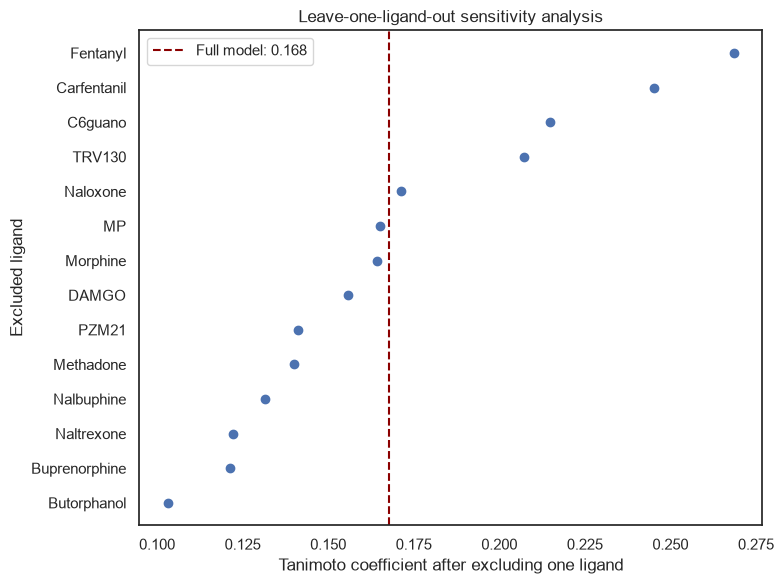

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    loo_results["beta_tanimoto"],
    loo_results["excluded_ligand"],
)

ax.axvline(
    baseline_beta,
    color="darkred",
    linestyle="--",
    label=f"Full model: {baseline_beta:.3f}",
)

ax.set(
    xlabel="Tanimoto coefficient after excluding one ligand",
    ylabel="Excluded ligand",
    title="Leave-one-ligand-out sensitivity analysis",
)
ax.legend()

fig.tight_layout()
plt.show()